##### The goal of this exercise is to get into some first contact with Python, Pandas data frames, and the many opportunities how to quickly generate static charts from data frames.

For the first exercise, load the provided CSV file, do some data cleaning, and check if your cleaning operation was successful using visualization. For inspiration, browse through some Kaggle notebooks. The original data was downloaded from Kaggle. 

The main purpose of the notebook is to preprocess the CSV file for further visualization. The following steps have to be performed: 

- Read the CSV using Pandas. The data has been slightly preprocessed in Excel to clean and simplify it. See the pandas.read_csv documentation to check how to parse the CSV correctly! (0.5 points)
- Remove unusable rows. The provided CSV may contain rows containing aggregated values or headers we do not need for our final visualization (we are only interested in the individual indicators, not their grouping into pre-defined categories). These rows need to be removed. (0.75 points)
- Take care of missing values. Sci-kit learn provides different data imputation methods. (0.75 points)
    (Hint: You may need to impute before you completely filter your data-frame. You need to make an educated judgment). 
- Visualize the data (twice). Every submitted notebook should contain at least two visualizations using at least two different Python visualization libraries. A list of the most wide-spread Python visualization libraries can be found in this article. You must concisely describe and explain each visualization and your decisions in a Markdown field. You will not receive the points for this task if you did not add a description/explanation. (max. 1.25 points per visualization) Only the first two visualizations will be graded. Submitting more than two visualizations will not result in additional points.
- Save the resulting table as CSV. To be sure that the data is correctly saved, you can load it again. You will have to work with this clean dataset for the second exercise. (0.5 points)


In [6]:
import pandas as pd

df = pd.read_csv("./dataset/agriRuralDevelopment.csv")
print(f"Dataset shape: {df.shape[0]:,} observations, {df.shape[1]} features")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print()
print("Column types:")
print(df.dtypes.to_string())

Dataset shape: 13,908 observations, 55 features
Memory usage: 7.10 MB

Column types:
Country Name                                                                                      str
Country Code                                                                                      str
year                                                                                            int64
Access to electricity (% of population)                                                       float64
Access to electricity, rural (% of rural population)                                          float64
Agricultural irrigated land (% of total agricultural land)                                    float64
Agricultural land (% of land area)                                                            float64
Agricultural land (sq. km)                                                                    float64
Agricultural machinery, tractors                                                              float

### Removing non-country aggregate rows

A preliminary inspection of the dataset shows that some entries represent **regional or economic aggregates** (e.g., *European Union*, *Arab World*, *World*) rather than individual countries. Since this assignment focuses on **country-level analysis**, these rows are not suitable and are removed before further preprocessing.  

In [7]:
aggregates = {
    "Arab World",
    "Caribbean small states",
    "Central Europe and the Baltics",
    "East Asia & Pacific",
    "Europe & Central Asia",
    "European Union",
    "Middle East & North Africa",
    "North America",
    "Small states",
    "World"
}

df = df[~df["Country Name"].isin(aggregates)]

In [8]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
}).sort_values('Missing %', ascending=False)

print(missing_df.to_string())
print(f"\nTotal missing values in entire dataset: {missing.sum()}")

                                                                                            Missing Count  Missing %
Rural land area where elevation is below 5 meters (sq. km)                                          12758      95.94
Rural land area where elevation is below 5 meters (% of total land area)                            12758      95.94
Rural land area (sq. km)                                                                            12758      95.94
Rural population living in areas where elevation is below 5 meters (% of total population)          12758      95.94
Annual freshwater withdrawals, agriculture (% of total freshwater withdrawal)                       12737      95.78
Agricultural irrigated land (% of total agricultural land)                                          12464      93.73
Literacy rate, adult total (% of people ages 15 and above)                                          12250      92.12
Fertilizer consumption (% of fertilizer production)             

### Missing-data assessment and imputation strategy

Before applying any imputation method, we compute the number and percentage of missing values per column. This step is essential because it reveals the *structure* of missingness (which variables are affected, and to what extent), not just the total amount of missing data. In practice, variables with very high missingness may require different treatment than variables with only occasional gaps.

For this dataset, observations are repeated over time for each country, so missing values should be handled in a way that respects this panel-like structure. The imputation strategy used is **median imputation**, which is less sensitive to extreme values than mean imputation and is therefore appropriate for socio-economic indicators that may be skewed.

Therefore, imputation is performed in two stages:

1. **Within-country median fill** (grouped by country code), to preserve country-specific level differences over time.
2. **Global median imputation** (via `SimpleImputer`) for remaining missing entries in usable numeric columns.

In [ ]:
from sklearn.impute import SimpleImputer

id_cols = ["Country Name", "Country Code", "year"]
value_cols = [c for c in df.columns if c not in id_cols]

country_medians = df.groupby("Country Code")[value_cols].transform("median")
df[value_cols] = df[value_cols].fillna(country_medians)

usable_value_cols = [c for c in value_cols if not df[c].isna().all()]
all_nan_cols = [c for c in value_cols if df[c].isna().all()]
# Columns with no usable data
print(all_nan_cols)

if usable_value_cols:
    imputer = SimpleImputer(strategy="median")
    df[usable_value_cols] = imputer.fit_transform(df[usable_value_cols])

missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
}).sort_values('Missing %', ascending=False)

print(missing_df.to_string())
print(f"\nTotal missing values in entire dataset: {missing.sum()}")

[]
                                                                                            Missing Count  Missing %
Country Name                                                                                            0        0.0
Country Code                                                                                            0        0.0
year                                                                                                    0        0.0
Access to electricity (% of population)                                                                 0        0.0
Access to electricity, rural (% of rural population)                                                    0        0.0
Agricultural irrigated land (% of total agricultural land)                                              0        0.0
Agricultural land (% of land area)                                                                      0        0.0
Agricultural land (sq. km)                                   

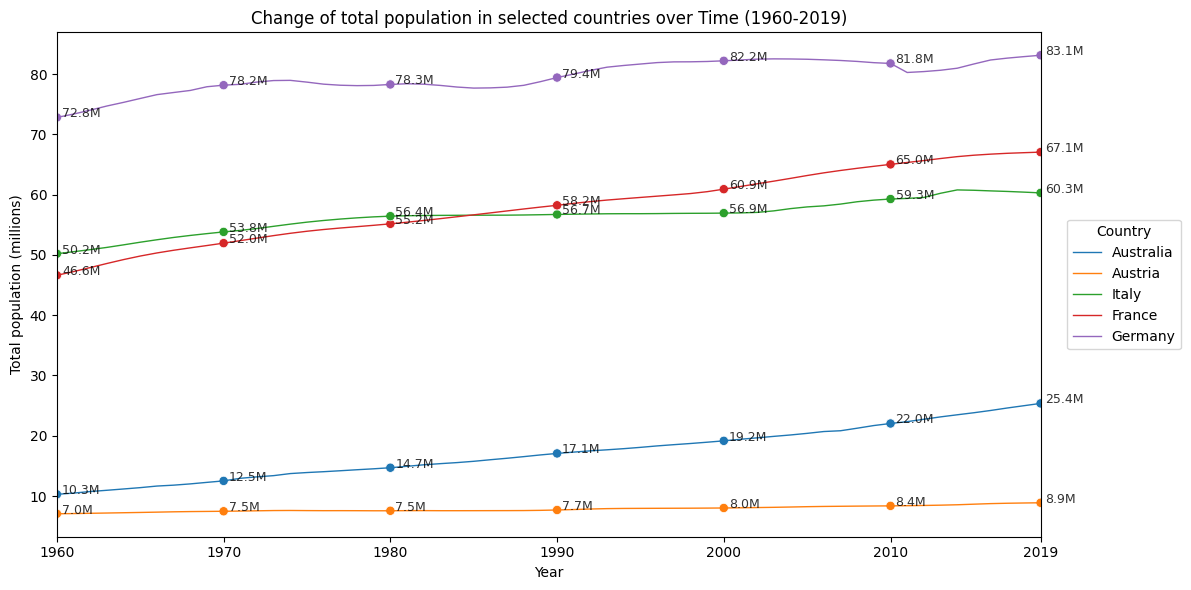

In [10]:
# Population vs Year: selected countries (up to 2019) with decade value points
import seaborn as sns
import matplotlib.pyplot as plt

pop_col = "Population, total"

plot_df = df[["Country Name", "year", pop_col]].copy()
plot_df["year"] = pd.to_numeric(plot_df["year"], errors="coerce")
plot_df[pop_col] = pd.to_numeric(plot_df[pop_col], errors="coerce")
plot_df = plot_df.dropna(subset=["year", pop_col])

plot_df = plot_df[plot_df["year"] <= 2019]

selected_countries = ["Austria", "Australia", "Germany", "France", "Italy"]

plot_subset = plot_df[plot_df["Country Name"].isin(selected_countries)].copy()
plot_subset["year"] = plot_subset["year"].astype(int)
plot_subset = plot_subset.sort_values("year")

plot_subset[pop_col] = plot_subset[pop_col] / 1e6

plt.figure(figsize=(12, 6))
ax = sns.lineplot(
    data=plot_subset,
    x="year",
    y=pop_col,
    hue="Country Name",
    linewidth=1
)

decade_points = plot_subset[(plot_subset["year"] % 10 == 0) | (plot_subset["year"] == 2019)]
sns.scatterplot(
    data=decade_points,
    x="year",
    y=pop_col,
    hue="Country Name",
    legend=False,
    s=45,
    ax=ax
)

for _, row in decade_points.iterrows():
    ax.text(
        row["year"] + 0.3,
        row[pop_col],
        f"{row[pop_col]:.1f}M",
        fontsize=9,
        alpha=0.8
    )

plt.title("Change of total population in selected countries over Time (1960-2019)")
plt.xlabel("Year")
plt.ylabel("Total population (millions)")
plt.xlim(plot_subset["year"].min(), 2019)

start_year = int(plot_subset["year"].min())
decade_start = (start_year // 10) * 10
x_ticks = sorted(set(list(range(decade_start, 2020, 10)) + [2019]))
plt.xticks(x_ticks)

plt.legend(title="Country", bbox_to_anchor=(1.02, 0.5), loc="center left")
plt.tight_layout()
plt.show()

### Visualization: Change of total population in selected countries over time (1960–2019)
This Seaborn line chart shows total population trends for **Austria, Australia, Germany, France, and Italy** from **1960 to 2019**.

**What the visualization shows:**
- **Germany** has the largest population in this selected group across most years.
- **France** and **Italy** are in the middle range, with gradual long-term growth.
- **Australia** starts from a lower base but grows strongly and consistently.
- **Austria** remains the smallest in the group with moderate growth.

**Design decisions:**
- A **line chart** is used because population is time-series data and trends are the key focus.
- The data is filtered to years **up to 2019** due to missing values in year **2020**.
- Population values are scaled to **millions ($1e6$)**, improving readability of the y-axis.
- **Markers are added every 10 years** (1960, 1970, …, 2010) plus **2019**, and each marker is annotated with its value (e.g., `67.4M`) to make exact decade-level comparisons easier.
- A single combined figure with color-coded lines supports direct cross-country comparison.